# Task 1

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("heart.csv")
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,Male,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,Male,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,Male,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,Male,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,Female,0,138,294,1,1,106,0,1.9,1,3,2,0


In [3]:
df.shape, df.columns.tolist()

((1025, 14),
 ['age',
  'sex',
  'cp',
  'trestbps',
  'chol',
  'fbs',
  'restecg',
  'thalach',
  'exang',
  'oldpeak',
  'slope',
  'ca',
  'thal',
  'target'])

In [4]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [5]:
df["target"].value_counts()

target
1    526
0    499
Name: count, dtype: int64

In [6]:
categorical_features = ["sex"]
numeric_features = [col for col in df.columns if col not in categorical_features + ["target"]]
X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [7]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=160, max_depth=8, min_samples_leaf=2,
        random_state=42, class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['age','sex','cp',...,'slope','ca','thal']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining co

In [8]:
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, probabilities), 4))
print(classification_report(y_test, predictions))

Accuracy: 0.9805
ROC-AUC: 0.999
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       100
           1       0.98      0.98      0.98       105

    accuracy                           0.98       205
   macro avg       0.98      0.98      0.98       205
weighted avg       0.98      0.98      0.98       205



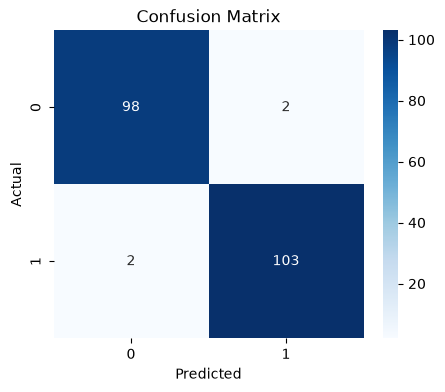

In [9]:
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, predictions), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [10]:
usability_heuristics = pd.DataFrame({
    "Heuristic": [
        "Visibility of system status",
        "Match with real-world language",
        "User control and freedom",
        "Consistency and standards",
        "Error prevention",
        "Recognition rather than recall",
        "Flexibility and efficiency",
        "Aesthetic and minimalist design",
        "Error recovery",
        "Help and documentation"
    ],
    "Review question": [
        "Are prediction progress and results clearly visible?",
        "Are medical input labels understandable?",
        "Can users change inputs and reset values easily?",
        "Do controls and result labels behave consistently?",
        "Are impossible or out-of-range values blocked?",
        "Are input ranges and examples visible?",
        "Can users update several inputs without restarting?",
        "Is the screen focused on essential information?",
        "Are validation messages clear and actionable?",
        "Is a short explanation available for each result?"
    ],
    "Status": ["Needs testing"] * 10,
    "Observation": [""] * 10
})
display(usability_heuristics)

,Heuristic,Review question,Status,Observation
0,Visibility of system status,Are prediction progress and results clearly vi...,Needs testing,
1,Match with real-world language,Are medical input labels understandable?,Needs testing,
2,User control and freedom,Can users change inputs and reset values easily?,Needs testing,
3,Consistency and standards,Do controls and result labels behave consisten...,Needs testing,
4,Error prevention,Are impossible or out-of-range values blocked?,Needs testing,
5,Recognition rather than recall,Are input ranges and examples visible?,Needs testing,
6,Flexibility and efficiency,Can users update several inputs without restar...,Needs testing,
7,Aesthetic and minimalist design,Is the screen focused on essential information?,Needs testing,
8,Error recovery,Are validation messages clear and actionable?,Needs testing,
9,Help and documentation,Is a short explanation available for each result?,Needs testing,


In [11]:
feedback_columns = [
    "Participant", "Device", "Task attempted", "What worked",
    "Pain point", "Suggested improvement", "Severity (1-5)"
]
feedback = pd.DataFrame(columns=feedback_columns)
feedback

,Participant,Device,Task attempted,What worked,Pain point,Suggested improvement,Severity (1-5)


In [12]:
def add_feedback(participant, device, task, worked, pain_point, suggestion, severity):
    global feedback
    new_feedback = pd.DataFrame([{
        "Participant": participant,
        "Device": device,
        "Task attempted": task,
        "What worked": worked,
        "Pain point": pain_point,
        "Suggested improvement": suggestion,
        "Severity (1-5)": int(severity)
    }])
    feedback = pd.concat([feedback, new_feedback], ignore_index=True)
    return feedback

add_feedback(
    "Example participant", "Laptop", "Enter values and view prediction",
    "Input labels were easy to follow",
    "The meaning of the probability was not immediately clear",
    "Add a short explanation beside the probability", 3
)

,Participant,Device,Task attempted,What worked,Pain point,Suggested improvement,Severity (1-5)
0,Example participant,Laptop,Enter values and view prediction,Input labels were easy to follow,The meaning of the probability was not immedia...,Add a short explanation beside the probability,3


In [13]:
def usability_summary(feedback_data):
    if feedback_data.empty:
        return "No feedback has been entered yet."
    print("Feedback entries:", len(feedback_data))
    print("Average severity:", round(feedback_data["Severity (1-5)"].mean(), 2))
    print("Most frequent pain points:")
    display(feedback_data["Pain point"].value_counts().head(5))
    print("Suggested improvements:")
    display(feedback_data[["Pain point", "Suggested improvement", "Severity (1-5)"]])

usability_summary(feedback)

Feedback entries: 1
Average severity: 3.0
Most frequent pain points:


Pain point
The meaning of the probability was not immediately clear    1
Name: count, dtype: int64

Suggested improvements:


,Pain point,Suggested improvement,Severity (1-5)
0,The meaning of the probability was not immedia...,Add a short explanation beside the probability,3


In [14]:
usability_improvements = pd.DataFrame({
    "Observed risk": [
        "Unclear probability meaning",
        "Invalid numeric entries",
        "Too many controls on a small screen",
        "No quick way to restore original values"
    ],
    "Interface refinement": [
        "Show the probability as an estimate and explain both classes",
        "Set realistic slider limits and validate every value",
        "Use a compact responsive layout and group related inputs",
        "Add a reset control"
    ]
})
display(usability_improvements)

,Observed risk,Interface refinement
0,Unclear probability meaning,Show the probability as an estimate and explai...
1,Invalid numeric entries,Set realistic slider limits and validate every...
2,Too many controls on a small screen,Use a compact responsive layout and group rela...
3,No quick way to restore original values,Add a reset control


# Task 2

In [15]:
import ipywidgets as widgets
from IPython.display import display, clear_output
import plotly.graph_objects as go
from plotly.subplots import make_subplots

In [16]:
default_values = {
    "age": int(X["age"].median()),
    "sex": X["sex"].mode()[0],
    "cp": int(X["cp"].mode()[0]),
    "trestbps": int(X["trestbps"].median()),
    "chol": int(X["chol"].median()),
    "fbs": int(X["fbs"].mode()[0]),
    "restecg": int(X["restecg"].mode()[0]),
    "thalach": int(X["thalach"].median()),
    "exang": int(X["exang"].mode()[0]),
    "oldpeak": float(X["oldpeak"].median()),
    "slope": int(X["slope"].mode()[0]),
    "ca": int(X["ca"].mode()[0]),
    "thal": int(X["thal"].mode()[0])
}
default_values

{'age': 56,
 'sex': 'Male',
 'cp': 0,
 'trestbps': 130,
 'chol': 240,
 'fbs': 0,
 'restecg': 1,
 'thalach': 152,
 'exang': 0,
 'oldpeak': 0.8,
 'slope': 1,
 'ca': 0,
 'thal': 2}

In [17]:
slider_specs = {
    "age": (int(X.age.min()), int(X.age.max()), 1),
    "cp": (int(X.cp.min()), int(X.cp.max()), 1),
    "trestbps": (int(X.trestbps.min()), int(X.trestbps.max()), 1),
    "chol": (int(X.chol.min()), int(X.chol.max()), 1),
    "fbs": (int(X.fbs.min()), int(X.fbs.max()), 1),
    "restecg": (int(X.restecg.min()), int(X.restecg.max()), 1),
    "thalach": (int(X.thalach.min()), int(X.thalach.max()), 1),
    "exang": (int(X.exang.min()), int(X.exang.max()), 1),
    "oldpeak": (float(X.oldpeak.min()), float(X.oldpeak.max()), 0.1),
    "slope": (int(X.slope.min()), int(X.slope.max()), 1),
    "ca": (int(X.ca.min()), int(X.ca.max()), 1),
    "thal": (int(X.thal.min()), int(X.thal.max()), 1)
}

In [18]:
controls = {}
for feature, (minimum, maximum, step) in slider_specs.items():
    controls[feature] = widgets.FloatSlider(
        value=default_values[feature],
        min=minimum,
        max=maximum,
        step=step,
        description=feature,
        continuous_update=False,
        readout=True,
        layout=widgets.Layout(width="95%")
    )

controls["sex"] = widgets.Dropdown(
    options=sorted(X["sex"].dropna().unique().tolist()),
    value=default_values["sex"],
    description="sex",
    layout=widgets.Layout(width="95%")
)

reset_button = widgets.Button(description="Reset inputs", button_style="warning")
result_output = widgets.Output()
chart_output = widgets.Output()

In [19]:
def current_input():
    values = {name: control.value for name, control in controls.items()}
    for name in slider_specs:
        if slider_specs[name][2] == 1:
            values[name] = int(round(values[name]))
    return pd.DataFrame([values])[X.columns]

In [20]:
def update_prediction(change=None):
    sample = current_input()
    probability = float(model.predict_proba(sample)[0, 1])
    prediction = int(probability >= 0.5)

    with result_output:
        clear_output(wait=True)
        label = "Higher model-estimated likelihood" if prediction == 1 else "Lower model-estimated likelihood"
        print("Model output:", label)
        print("Estimated probability for target = 1:", f"{probability:.1%}")
        print("This is an educational model output, not a medical diagnosis.")

    with chart_output:
        clear_output(wait=True)
        figure = go.Figure(go.Bar(
            x=["Target 0", "Target 1"],
            y=[1 - probability, probability],
            text=[f"{1-probability:.1%}", f"{probability:.1%}"],
            textposition="auto"
        ))
        figure.update_layout(
            title="Prediction probability",
            yaxis_title="Probability",
            yaxis=dict(range=[0, 1]),
            height=320
        )
        display(figure)

for control in controls.values():
    control.observe(update_prediction, names="value")

def reset_inputs(button):
    for name, control in controls.items():
        control.value = default_values[name]

reset_button.on_click(reset_inputs)
update_prediction()

In [21]:
input_panel = widgets.VBox([
    widgets.HTML("<h3>Patient input controls</h3>"),
    *[controls[name] for name in [
        "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
        "thalach", "exang", "oldpeak", "slope", "ca", "thal"
    ]],
    reset_button
], layout=widgets.Layout(width="100%", max_width="760px"))

display(input_panel, result_output, chart_output)

Output()

Output()

In [22]:
feature_ranges = pd.DataFrame({
    "Feature": X.columns,
    "Minimum": [X[c].min() for c in X.columns],
    "Median": [X[c].median() if pd.api.types.is_numeric_dtype(X[c]) else X[c].mode()[0] for c in X.columns],
    "Maximum": [X[c].max() for c in X.columns]
})
display(feature_ranges)

,Feature,Minimum,Median,Maximum
0,age,29,56.0,77
1,sex,Female,Male,Male
2,cp,0,1.0,3
3,trestbps,94,130.0,200
4,chol,126,240.0,564
5,fbs,0,0.0,1
6,restecg,0,1.0,2
7,thalach,71,152.0,202
8,exang,0,0.0,1
9,oldpeak,0.0,0.8,6.2


# Task 3

In [23]:
from math import factorial
from itertools import combinations

In [24]:
background = X_train.sample(
    n=min(20, len(X_train)), random_state=42
).reset_index(drop=True)

feature_names = X.columns.tolist()
feature_count = len(feature_names)
baseline_probability = float(
    model.predict_proba(background)[..., 1].mean()
)
baseline_probability

0.3921432101044499

In [25]:
def coalition_value(sample, feature_subset):
    batch = background.copy()
    for feature_index in feature_subset:
        feature = feature_names[feature_index]
        batch[feature] = sample.iloc[0][feature]
    return float(model.predict_proba(batch)[:, 1].mean())

In [26]:
def exact_shap_values(sample):
    values = {}
    coalition_cache = {}

    for mask in range(1 << feature_count):
        subset = tuple(
            index for index in range(feature_count)
            if mask & (1 << index)
        )
        coalition_cache[mask] = coalition_value(sample, subset)

    for feature_index, feature in enumerate(feature_names):
        contribution = 0.0
        for mask in range(1 << feature_count):
            if mask & (1 << feature_index):
                continue

            subset_size = int(mask.bit_count())
            weight = (
                factorial(subset_size) *
                factorial(feature_count - subset_size - 1) /
                factorial(feature_count)
            )
            with_feature = mask | (1 << feature_index)
            contribution += weight * (
                coalition_cache[with_feature] - coalition_cache[mask]
            )
        values[feature] = contribution

    return pd.Series(values).sort_values(key=abs, ascending=False)

In [27]:
sample_for_explanation = current_input()
shap_values = exact_shap_values(sample_for_explanation)
shap_values

ca          0.151593
thal        0.101338
exang       0.067821
age         0.045476
cp         -0.039138
thalach     0.037832
oldpeak     0.023743
sex        -0.023163
slope      -0.018811
chol        0.013998
trestbps    0.010742
restecg     0.002844
fbs         0.002014
dtype: float64

In [28]:
explainer_base = baseline_probability
explained_probability = float(model.predict_proba(sample_for_explanation)[0, 1])
shap_total = explainer_base + shap_values.sum()

print("Baseline probability:", round(explainer_base, 4))
print("Model probability:", round(explained_probability, 4))
print("Baseline + SHAP contributions:", round(float(shap_total), 4))
print("Difference:", round(float(explained_probability - shap_total), 6))

Baseline probability: 0.3921
Model probability: 0.7684
Baseline + SHAP contributions: 0.7684
Difference: 0.0


In [29]:
def plot_shap_values(values):
    ordered = values.sort_values()
    figure = go.Figure(go.Bar(
        x=ordered.values,
        y=ordered.index,
        orientation="h",
        marker=dict(color=[
            "indianred" if value < 0 else "seagreen"
            for value in ordered.values
        ]),
        text=[f"{value:+.4f}" for value in ordered.values],
        textposition="outside"
    ))
    figure.update_layout(
        title="Feature contributions for the selected input",
        xaxis_title="Contribution to target = 1 probability",
        yaxis_title="Feature",
        height=520,
        margin=dict(l=110, r=40, t=60, b=50)
    )
    figure.add_vline(x=0, line_dash="dash", line_color="gray")
    return figure

display(plot_shap_values(shap_values))

In [30]:
feature_picker = widgets.Dropdown(
    options=feature_names,
    value=shap_values.index[0],
    description="Feature"
)
detail_output = widgets.Output()

def show_feature_detail(change=None):
    feature = feature_picker.value
    contribution = float(shap_values[feature])
    with detail_output:
        clear_output(wait=True)
        direction = "increases" if contribution > 0 else "decreases"
        print("Feature:", feature)
        print("Input value:", sample_for_explanation.iloc[0][feature])
        print("Contribution:", round(contribution, 5))
        print("This feature", direction, "the model-estimated probability relative to the baseline.")

feature_picker.observe(show_feature_detail, names="value")
show_feature_detail()
display(feature_picker, detail_output)

Dropdown(description='Feature', index=11, options=('age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', '…

Output()

In [31]:
shap_summary = pd.DataFrame({
    "Feature": shap_values.index,
    "SHAP value": shap_values.values,
    "Absolute contribution": np.abs(shap_values.values)
}).reset_index(drop=True)

display(shap_summary)

,Feature,SHAP value,Absolute contribution
0,ca,0.151593,0.151593
1,thal,0.101338,0.101338
2,exang,0.067821,0.067821
3,age,0.045476,0.045476
4,cp,-0.039138,0.039138
5,thalach,0.037832,0.037832
6,oldpeak,0.023743,0.023743
7,sex,-0.023163,0.023163
8,slope,-0.018811,0.018811
9,chol,0.013998,0.013998


In [32]:
print("Interpretation")
print("Positive values move the model output toward target = 1.")
print("Negative values move the model output away from target = 1.")
print("The values use an interventional background sample from the training data.")
print("This manual exact Shapley calculation is for one selected input and may take time.")
print("Model explanations describe model behavior and do not establish medical causation.")

Interpretation
Positive values move the model output toward target = 1.
Negative values move the model output away from target = 1.
The values use an interventional background sample from the training data.
This manual exact Shapley calculation is for one selected input and may take time.
Model explanations describe model behavior and do not establish medical causation.
